# 白色矮星の色研究：追加解析と再現可能な判断

このノートブックは、**観測・単位・較正・識別情報を点検した結果、どの証拠を研究に使えるようになり、何が未確定か**を追うための実行済みの伴走資料です。

数値はrepo内の保存済み表・manifestから読み込みます。新たなサーベイ取得、膨大なMonte Carlo、LPの再求解は行いません。コードを上から再実行すると表と要点が更新されます。埋め込んだ既存図の再生成コードも各節に示します。

対象は今回の便宜標本です。色名・sRGB表示値・閾値外の点を、そのまま新天体の発見や母集団の発生率に読み替えません。

## 実行環境と入力

Pythonと依存はrepoの `requirements-core.txt` を使用します。カーネルの作業ディレクトリはrepo rootまたは `research/` で構いません。Gaia IDは18–19桁の**文字列**として読み、浮動小数点に変換しません。

In [1]:
from pathlib import Path
import hashlib, json, sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown, Image

def find_repo():
    for candidate in (Path.cwd(), *Path.cwd().parents):
        if (candidate / 'colour_pipeline.py').is_file() and (candidate / 'research').is_dir():
            return candidate
    raise FileNotFoundError('repo root または research/ を作業ディレクトリにしてください')

REPO = find_repo()
input_hashes = {}
def record_path(relative):
    path = REPO / relative
    input_hashes[relative] = hashlib.sha256(path.read_bytes()).hexdigest()
    return path
def read_json(relative):
    return json.loads(record_path(relative).read_text())
def read_table(relative):
    return pd.read_csv(record_path(relative), dtype={'source_id': 'string', 'entity_id': 'string', 'oid': 'string'})
def show_table(frame, formats=None):
    display(frame.style.hide(axis='index').format(formats or {}, na_rep='未取得')
            .set_properties(**{'text-align': 'left', 'padding': '6px 10px'})
            .set_table_styles([{'selector': 'th', 'props': [('text-align', 'left')]}]))
def show_figure(relative, width=1050):
    display(Image(data=record_path(relative).read_bytes(), width=width))

pd.set_option('display.max_colwidth', 70)

In [2]:
census = read_json('research/outlier_audit/census_summary.json')
corrected_summary = read_json('research/precision/flux_units/corrected_screen_summary.json')
unit_registry = read_json('research/precision/flux_convention_evidence.json')
ps1 = read_table('research/precision/candidate_recalibration/standardized_colours.csv')
gaia = read_table('research/precision/gaia_expanded/formal_colour_results.csv')
gaia_retrieval = read_json('research/precision/gaia_expanded/retrieval.json')
held_z = read_table('research/precision/candidate_recalibration/heldout_z.csv')
held_z_summary = read_json('research/precision/candidate_recalibration/heldout_z.json')
nullspace = read_table('research/precision/photometric_nullspace.csv')
visual_index = read_table('research/outlier_audit/contact_sheet_index.csv')
verification = read_json('research/verification.json')

HEADLINE = {
    '818833831355548928': 'J0913+4434',
    '3204436719718449280': 'J0429−0354',
    '3711047662972690688': 'J1329+0033',
    '3638333660492606976': 'J1323−0129',
}

## 要点

In [3]:
unit_counts = pd.Series([r['convention'] for r in unit_registry['records']]).value_counts()
z_valid = held_z.dropna(subset=['z_residual_predicted_minus_observed_mag'])
display(Markdown(f"""
- 元の **{census['records']:,}スペクトル記録**を保持したまま単位の扱いを修正しました。MWDD SDSSのFν形状を確認した原ファイルは **{unit_counts['fnu']:,}件**です。現行の採用記録は **{corrected_summary['current_eligible_records']:,}件**、強い外れ値を含むentity keyは **{corrected_summary['current_strong_entity_keys']:,}件**です。
- PS1の出典付きgri較正は **{ps1.status.eq('calibrated_conditional').sum()}/{len(ps1)}候補**で可能です。Gaiaの元係数・共分散からは **{gaia.source_id.nunique()}対象・{len(gaia)}再構成**を得ています。
- 較正に使っていないzとの比較は **{len(z_valid)}候補**で可能で、**{z_valid.z_residual_predicted_minus_observed_mag.abs().gt(.05).sum()}候補**に絶対値0.05 mag超の残差があります。これは有意度の判定ではありません。
- 個別の目視記録は **{len(visual_index)}/{census['review_entities']:,}要点検entity**をカバーします。全記録へのプログラム監査と、全要点検対象への目視完了は別の作業です。

現時点の成果は、**使える証拠の範囲と、追加検証で反証できる仮説を明確にしたこと**です。
"""))


- 元の **9,902スペクトル記録**を保持したまま単位の扱いを修正しました。MWDD SDSSのFν形状を確認した原ファイルは **149件**です。現行の採用記録は **7,473件**、強い外れ値を含むentity keyは **308件**です。
- PS1の出典付きgri較正は **25/27候補**で可能です。Gaiaの元係数・共分散からは **26対象・52再構成**を得ています。
- 較正に使っていないzとの比較は **25候補**で可能で、**10候補**に絶対値0.05 mag超の残差があります。これは有意度の判定ではありません。
- 個別の目視記録は **337/2,344要点検entity**をカバーします。全記録へのプログラム監査と、全要点検対象への目視完了は別の作業です。

現時点の成果は、**使える証拠の範囲と、追加検証で反証できる仮説を明確にしたこと**です。


## 背景と方法

[Hollands et al.『Any colour you like』](https://arxiv.org/html/2610.18966v1) は、Naによる緑系の色、C$_2$によるピンク系の色などを既に扱っています。同じ機構や既知対象に色名を付け直したことを、新たな物理的発見とは呼びません。

色はスペクトルからCIE1931等色関数でXYZへ積分し、CIE1960 $(u,v)$ と黒体軌跡からの距離で診断します。`Duv`は符号付きの診断量、採否の距離は `distance_planck_uv` です。閾値0.01は探索上の基準で、有意確率ではありません。HEXは規定のsRGB表示であり、肉眼で同じ色に見えることを保証しません。

### 解釈を支える仮定

- **スペクトル密度の約束を確認する。** $F_\lambda\propto F_\nu/\lambda^2$。波長に依存する変換なので、倍率の調節や3点の測光較正だけで代用できません。原データは保存し、未確認単位の現在色を保留します。
- **記録・星・独立観測を分ける。** entity keyには暫定位置照合が残ります。MWDDとSDSS直接配布が同じ元観測なら、別のアーカイブURLでも独立観測には増えません。
- **条件付き誤差を全誤差と呼ばない。** Gaiaの係数ノイズ、PS1アンカー、スペクトル画素ノイズだけで、波長相関のある較正誤差や非同時性まで説明できるとは仮定しません。
- **同じ情報を二重計上しない。** 同一スペクトルから求めた色と、そのスペクトルの全画素を別々の独立データとして尤度へ投入しません。

## 入力と出典

入力は保存済みの追加研究成果物です。表中のハッシュは表示用の先頭12桁で、コード中の `input_hashes` は完全なSHA256を保持します。原データまでのURL・完全なSHAは各manifestと `research/verification.json` にあります。

外部一次資料は [Swan et al. 2026](https://arxiv.org/html/2609.04314v1)、[Kilic et al. 2026](https://arxiv.org/html/2606.25377v2)、[Gaia DR3](https://www.cosmos.esa.int/web/gaia/dr3)、[DESI DR1](https://data.desi.lbl.gov/doc/releases/dr1/)、[PS1測光系](https://outerspace.stsci.edu/spaces/PANSTARRS/pages/298812303/PS1+Filter+properties) を参照します。データ帰属・利用条件・DESI指定謝辞は [literature/DATA_ACKNOWLEDGMENTS.md](literature/DATA_ACKNOWLEDGMENTS.md) に保存しています。

In [4]:
source_table = pd.DataFrame([
    {'保存済み入力': path.removeprefix('research/'), 'SHA256先頭12桁': digest[:12]}
    for path, digest in input_hashes.items()
])
show_table(source_table)

保存済み入力,SHA256先頭12桁
outlier_audit/census_summary.json,c95c19136db6
precision/flux_units/corrected_screen_summary.json,1fd1335b69fb
precision/flux_convention_evidence.json,00aef84a2e81
precision/candidate_recalibration/standardized_colours.csv,ff398fe0f5a3
precision/gaia_expanded/formal_colour_results.csv,6054c8dbca63
precision/gaia_expanded/retrieval.json,9485c5e6b4b2
precision/candidate_recalibration/heldout_z.csv,d7aa9848b041
precision/candidate_recalibration/heldout_z.json,bbb9e163b956
precision/photometric_nullspace.csv,38e0c52e8b43
outlier_audit/contact_sheet_index.csv,476b5847bb9f


## 結果

### 1. 単位の修正で、採用する証拠がどう変わったか

元の選択結果と、単位確認後の結果を同じ分母で比較します。未知の単位を除外した影響を含むため、減少分すべてが「誤った星」だったという意味ではありません。元の数値は `legacy_*` 列に保持されています。

In [5]:
census_table = pd.DataFrame([
    {'集計単位': 'スペクトル記録・全入力', '元の結果': census['records'], '単位確認後': corrected_summary['total_records']},
    {'集計単位': '色を採用できる記録', '元の結果': census['eligible_records'], '単位確認後': corrected_summary['current_eligible_records']},
    {'集計単位': '距離 ≥ 0.01 の採用記録', '元の結果': census['strong_outlier_records'], '単位確認後': corrected_summary['current_strong_records']},
    {'集計単位': '強い外れ値を含むentity key', '元の結果': census['strong_outlier_entities'], '単位確認後': corrected_summary['current_strong_entity_keys']},
])
show_table(census_table, {'元の結果': '{:,}', '単位確認後': '{:,}'})
unit_table = unit_counts.rename_axis('確認した原ファイルの規約').reset_index(name='ファイル数')
show_table(unit_table, {'ファイル数': '{:,}'})
display(Markdown(f"単位変換だけで新たに強い外れ値になったentity keyは **{corrected_summary['new_strong_entity_keys_from_conversion']}件**です。未確認単位は現在色を空欄にして採用から外しています。"))

集計単位,元の結果,単位確認後
スペクトル記録・全入力,"9,902","9,902"
色を採用できる記録,"9,023","7,473"
距離 ≥ 0.01 の採用記録,434,395
強い外れ値を含むentity key,337,308


確認した原ファイルの規約,ファイル数
unresolved,"1,579"
flambda,504
fnu,149


単位変換だけで新たに強い外れ値になったentity keyは **0件**です。未確認単位は現在色を空欄にして採用から外しています。

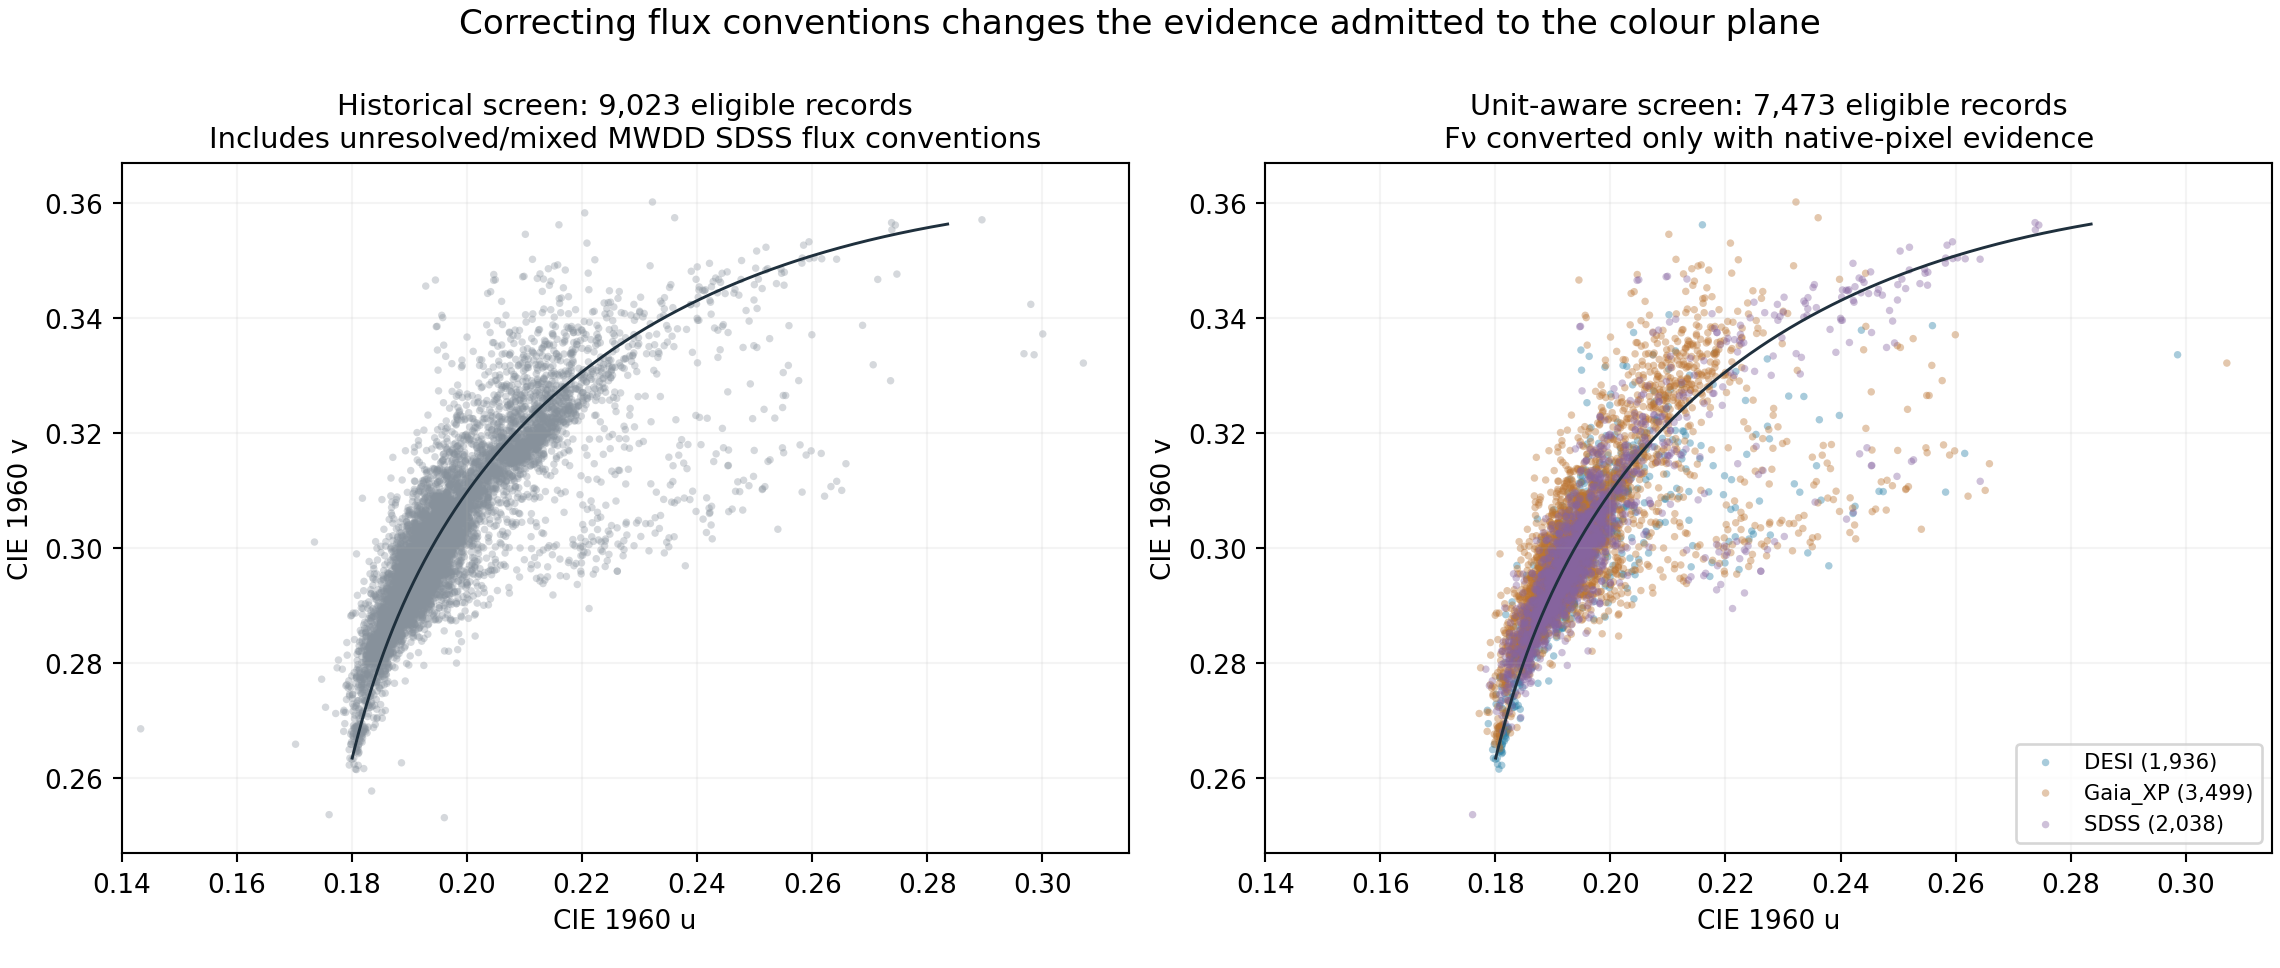

In [6]:
show_figure('research/precision/flux_units/corrected_colour_plane.png')

**図の読み方：** 左は単位未確認の記録を含む歴史的なscreen、右は今回の規約確認を反映したscreenです。同じ軸を使います。点の色はサーベイを区別するもので、星の表示色ではありません。割合から母集団の異常色WD頻度は推定できません。

図の生成元：`precision/flux_units/build_corrected_screen.py`。原観測の対応を成立させる条件と未解決例は [単位監査の説明](precision/flux_convention_audit.md) にあります。

### 2. 既存4候補を、同じPS1定義で較正する

Swanの観測PS1 gri AB等級を用いた結果です。元のscreenが別のアンカーを優先した場合とは区別します。PS1誤差のDR1/DR2差とfloorは [測光定義の検算](literature/swan_photometry_definition.md) で確認しました。測光だけの消光補正は加えていません。

下記の2.5–97.5%範囲は、採用した画素ノイズと較正パラメータのモデルに**条件を置いた区間**です。全系統誤差を含む95%区間や、発見の確率ではありません。

In [7]:
four = ps1.set_index('source_id').reindex(HEADLINE)
four_table = pd.DataFrame({
    '天体': [HEADLINE[sid] for sid in four.index],
    'HEX': four['hex'].to_numpy(),
    'Duv': four['duv'].to_numpy(),
    '条件付き2.5%': four['duv_mc_p025'].to_numpy(),
    '条件付き97.5%': four['duv_mc_p975'].to_numpy(),
})
show_table(four_table, {'Duv': '{:+.5f}', '条件付き2.5%': '{:+.5f}', '条件付き97.5%': '{:+.5f}'})

天体,HEX,Duv,条件付き2.5%,条件付き97.5%
J0913+4434,#F1FFC9,+0.01906,+0.01698,+0.02123
J0429−0354,#F8FFDC,+0.01281,+0.01197,+0.01365
J1329+0033,#FFC1CF,-0.02265,-0.02481,-0.02048
J1323−0129,#FFE96A,+0.02350,+0.02094,+0.02599


J1323−0129ではDESIの色推定が残る一方、単位未確認のMWDD SDSSを独立した色の裏付けとして扱うことは撤回しました。J1329+0033の別夜はC$_2$形状が残りますが、Zカメラ全体が無効で完全色の検証には使えません。観測間の不一致は保持し、平均して消しません。

### 3. Gaiaのfull / truncatedは同じデータの別再構成

元のXP係数・相関から、保存した較正設計行列を通してXYZ共分散まで伝播しています。fullと推奨打切りは**独立した2観測ではありません**。打切りによる系統差と、係数ノイズによる幅を分けて読む必要があります。

「緑最大割合」は、正のXYZという条件を通した係数ノイズの試行で緑成分が最大になった比率です。装置の較正、BP/RP間共分散、混入、選択関数を全て含む新発見の確率ではありません。

In [8]:
gaia_four = gaia[gaia.source_id.isin(HEADLINE)].copy()
gaia_four['天体'] = gaia_four.source_id.map(HEADLINE)
gaia_four['緑最大割合 [%]'] = 100 * gaia_four.formal_green_largest_fraction
gaia_table = gaia_four.rename(columns={
    'reconstruction': '再構成', 'duv': 'Duv', 'formal_duv_p025': '条件付き2.5%', 'formal_duv_p975': '条件付き97.5%'
})[['天体', '再構成', 'Duv', '条件付き2.5%', '条件付き97.5%', '緑最大割合 [%]']]
missing = [r for r in gaia_retrieval['results'] if r['status'] != 'downloaded']
for row in missing:
    if row['source_id'] in HEADLINE:
        gaia_table.loc[len(gaia_table)] = [HEADLINE[row['source_id']], '係数未取得', np.nan, np.nan, np.nan, np.nan]
show_table(gaia_table, {'Duv': '{:+.5f}', '条件付き2.5%': '{:+.5f}', '条件付き97.5%': '{:+.5f}', '緑最大割合 [%]': '{:.1f}'})
display(Markdown(f"全候補では **{gaia.source_id.nunique()}対象 × 2再構成 = {len(gaia)}件**です。係数の未取得は **{len(missing)}対象**として保持しています。"))

天体,再構成,Duv,条件付き2.5%,条件付き97.5%,緑最大割合 [%]
J0429−0354,full,+0.01299,+0.00869,+0.01730,82.3
J0429−0354,truncated,+0.01493,+0.01139,+0.01847,96.4
J1329+0033,full,-0.02451,-0.03276,-0.01623,0.0
J1329+0033,truncated,-0.02240,-0.03028,-0.01458,0.0
J0913+4434,full,+0.01923,+0.01238,+0.02614,85.3
J0913+4434,truncated,+0.01635,+0.00996,+0.02274,77.7
J1323−0129,係数未取得,未取得,未取得,未取得,未取得


全候補では **26対象 × 2再構成 = 52件**です。係数の未取得は **1対象**として保持しています。

### 4. 較正に使っていないzバンドを予測する

$\Delta z = z_{\rm spectrum} - z_{\rm PS1}$ と定義します。正ならスペクトルが予測するz光量の方が小さいことを示します。zを追加fitしていないため、griだけの較正が赤側でも通用するかを診断できます。ただし、同じPS1サーベイを共有し、iの赤端とも波長が重なります。

表は絶対残差0.05 mag超の対象を抽出したものです。閾値は診断上の表示条件で、有意性や棄却条件ではありません。

In [9]:
z_review = z_valid[z_valid.z_residual_predicted_minus_observed_mag.abs() > .05].copy()
z_review['絶対残差'] = z_review.z_residual_predicted_minus_observed_mag.abs()
z_review = z_review.sort_values('絶対残差', ascending=False)
z_review['欠損応答 [%]'] = 100 * z_review.z_invalid_photon_response_fraction_flat_flambda
z_table = z_review.rename(columns={
    'WDJname': '天体', 'z_residual_predicted_minus_observed_mag': 'Δz [mag]',
    'z_observed_error_mag': 'Swan z誤差 [mag]'
})[['天体', 'Δz [mag]', 'Swan z誤差 [mag]', '欠損応答 [%]']]
show_table(z_table, {'Δz [mag]': '{:+.4f}', 'Swan z誤差 [mag]': '{:.4f}', '欠損応答 [%]': '{:.3f}'})
display(Markdown(f"zの全応答を含むのは **{held_z_summary['full_z_passband']}件**、yは **{held_z_summary['full_y_passband']}件**です。yの赤端を外挿して埋めてはいません。"))

天体,Δz [mag],Swan z誤差 [mag],欠損応答 [%]
WDJ021739.29+011641.13,+0.0990,0.0192,0.474
WDJ125552.90+671244.24,-0.0897,0.0323,0.001
WDJ170205.24+150734.88,-0.0896,0.0214,0.200
WDJ132312.76-012923.67,-0.0815,0.0159,0.312
WDJ125802.76+050040.26,-0.0689,0.0263,0.001
WDJ011124.78-053318.52,-0.0679,0.0172,0.000
WDJ103113.86-013925.39,+0.0644,0.0199,1.760
WDJ042944.71-035422.00,-0.0610,0.0139,0.399
WDJ071637.37+621710.78,-0.0557,0.0113,1.643
WDJ150038.15+134301.74,+0.0513,0.0144,0.009


zの全応答を含むのは **25件**、yは **0件**です。yの赤端を外挿して埋めてはいません。

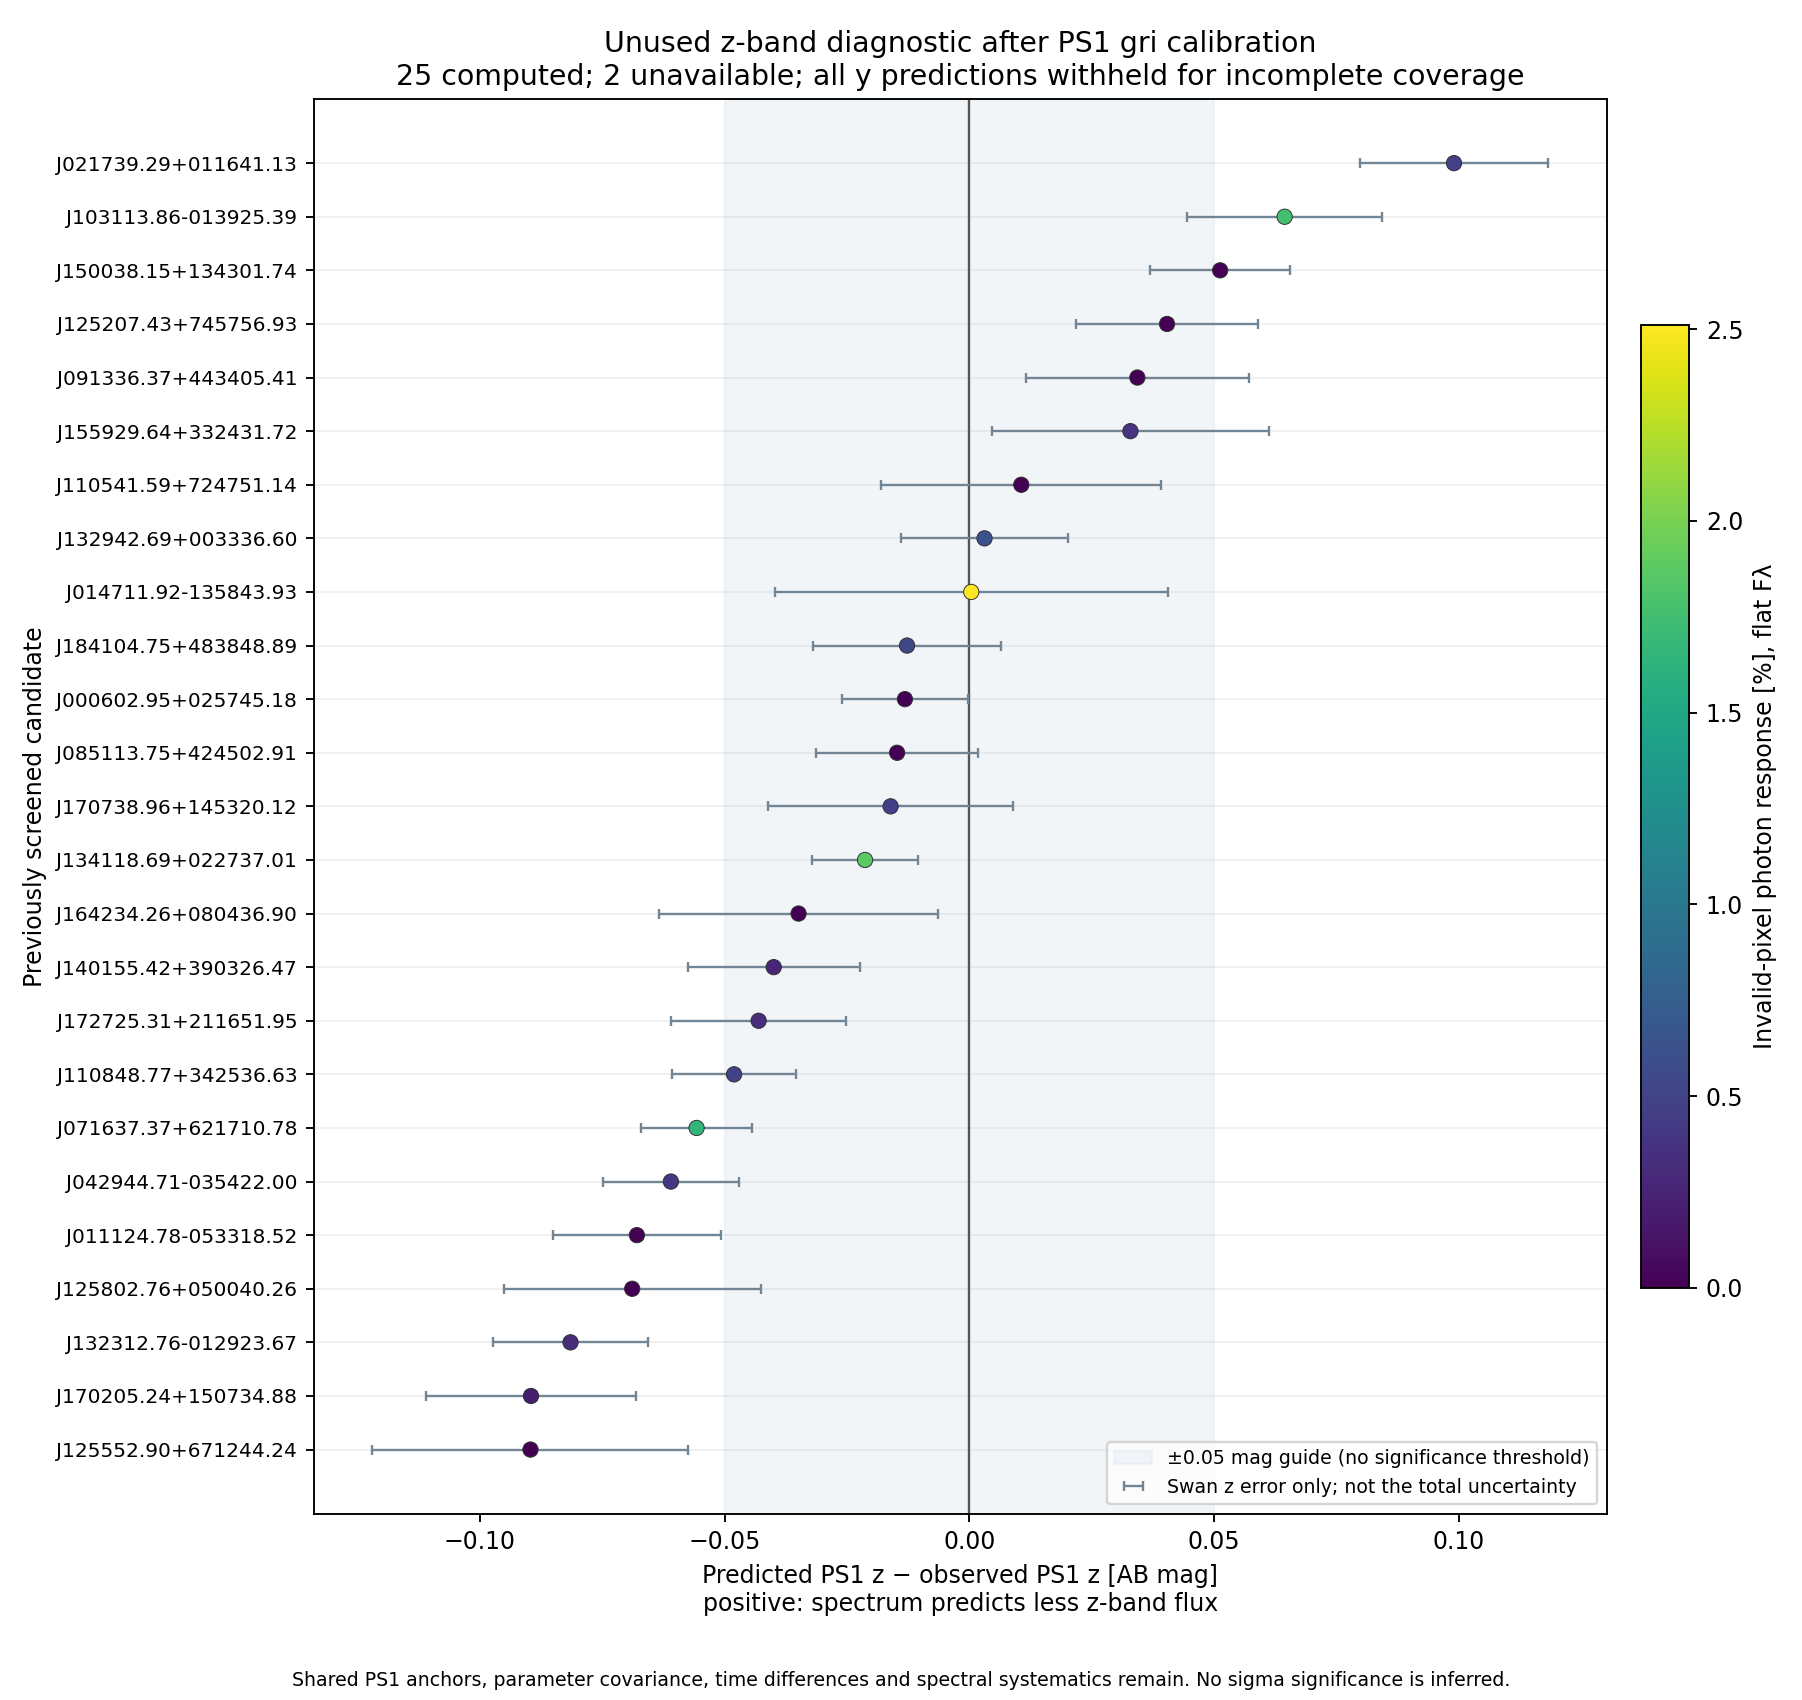

In [10]:
show_figure('research/precision/candidate_recalibration/heldout_z.png', width=920)

In [11]:
display(Markdown(f"""
**図の誤差棒はSwanのz誤差だけ**で、全誤差ではありません。入力には符号付きのfluxを用います。
最大欠損応答は **{100 * held_z_summary['maximum_invalid_response_fraction']:.3f}%**、
有効画素間の最大間隔は **{held_z_summary['maximum_valid_sample_gap_A']:.1f} Å**です。
最近傍埋めと線形補間の差は最大 **{held_z_summary['maximum_absolute_nearest_fill_stress_mag']:.6f} mag**でした。
これらは欠損の真のfluxや誤差上限を測った値ではありません。

生成元：`precision/candidate_recalibration/heldout_z.py`。較正パラメータ共分散、非同時性、空・大気・サーベイの系統誤差を含めず、残差を単純なnσには換算しません。
"""))


**図の誤差棒はSwanのz誤差だけ**で、全誤差ではありません。入力には符号付きのfluxを用います。
最大欠損応答は **2.511%**、
有効画素間の最大間隔は **21.6 Å**です。
最近傍埋めと線形補間の差は最大 **0.000529 mag**でした。
これらは欠損の真のfluxや誤差上限を測った値ではありません。

生成元：`precision/candidate_recalibration/heldout_z.py`。較正パラメータ共分散、非同時性、空・大気・サーベイの系統誤差を含めず、残差を単純なnσには換算しません。


### 5. griが一致しても、色が一意に決まるとは限らない

スペクトルへ滑らかな乗数 $1+\delta(\lambda)>0$ を掛け、**3バンドの合成光量を保存したまま**線形sRGBのG−RまたはG−Bをゼロにする摂動を探した実験です。最大変形量を小さくするLPと、連続splineの極値点検を用いています。

表の百分率は、各spline空間で得たwitnessの最大相対変形量です。**実際のDESI較正誤差の推定・確率・大気モデルの変化ではありません**。knot間隔も装置の相関長を測ったものではありません。

In [12]:
null_summary = nullspace.copy()
null_summary['最大変形 [%]'] = 100 * null_summary.supremum_witness_upper_bound
null_table = null_summary.pivot(index=['candidate', 'spacing_A'], columns='colour_boundary', values='最大変形 [%]').reset_index()
null_table.columns.name = None
null_table = null_table.rename(columns={'candidate': '天体', 'spacing_A': 'knot間隔 [Å]', 'G-R': 'G−R=0 [%]', 'G-B': 'G−B=0 [%]'})
show_table(null_table, {'G−R=0 [%]': '{:.2f}', 'G−B=0 [%]': '{:.2f}'})
display(Markdown(f"保存済み **{len(nullspace)} witness**の最大gri残差は **{nullspace.synthetic_gri_max_residual_mag.max():.2e} mag**、数値上下限の最大gapは **{nullspace.supremum_bound_gap.max():.2e}**です。実際の合成測光と連続極値の再計算は末尾の検証スクリプトで行います。"))

天体,knot間隔 [Å],G−B=0 [%],G−R=0 [%]
J0429-0354,400,16.30,4.27
J0429-0354,800,18.69,6.49
J0429-0354,1600,26.17,12.18
J0913+4434,400,27.35,7.94
J0913+4434,800,30.64,11.87
J0913+4434,1600,46.14,29.06


保存済み **12 witness**の最大gri残差は **9.13e-10 mag**、数値上下限の最大gapは **1.84e-09**です。実際の合成測光と連続極値の再計算は末尾の検証スクリプトで行います。

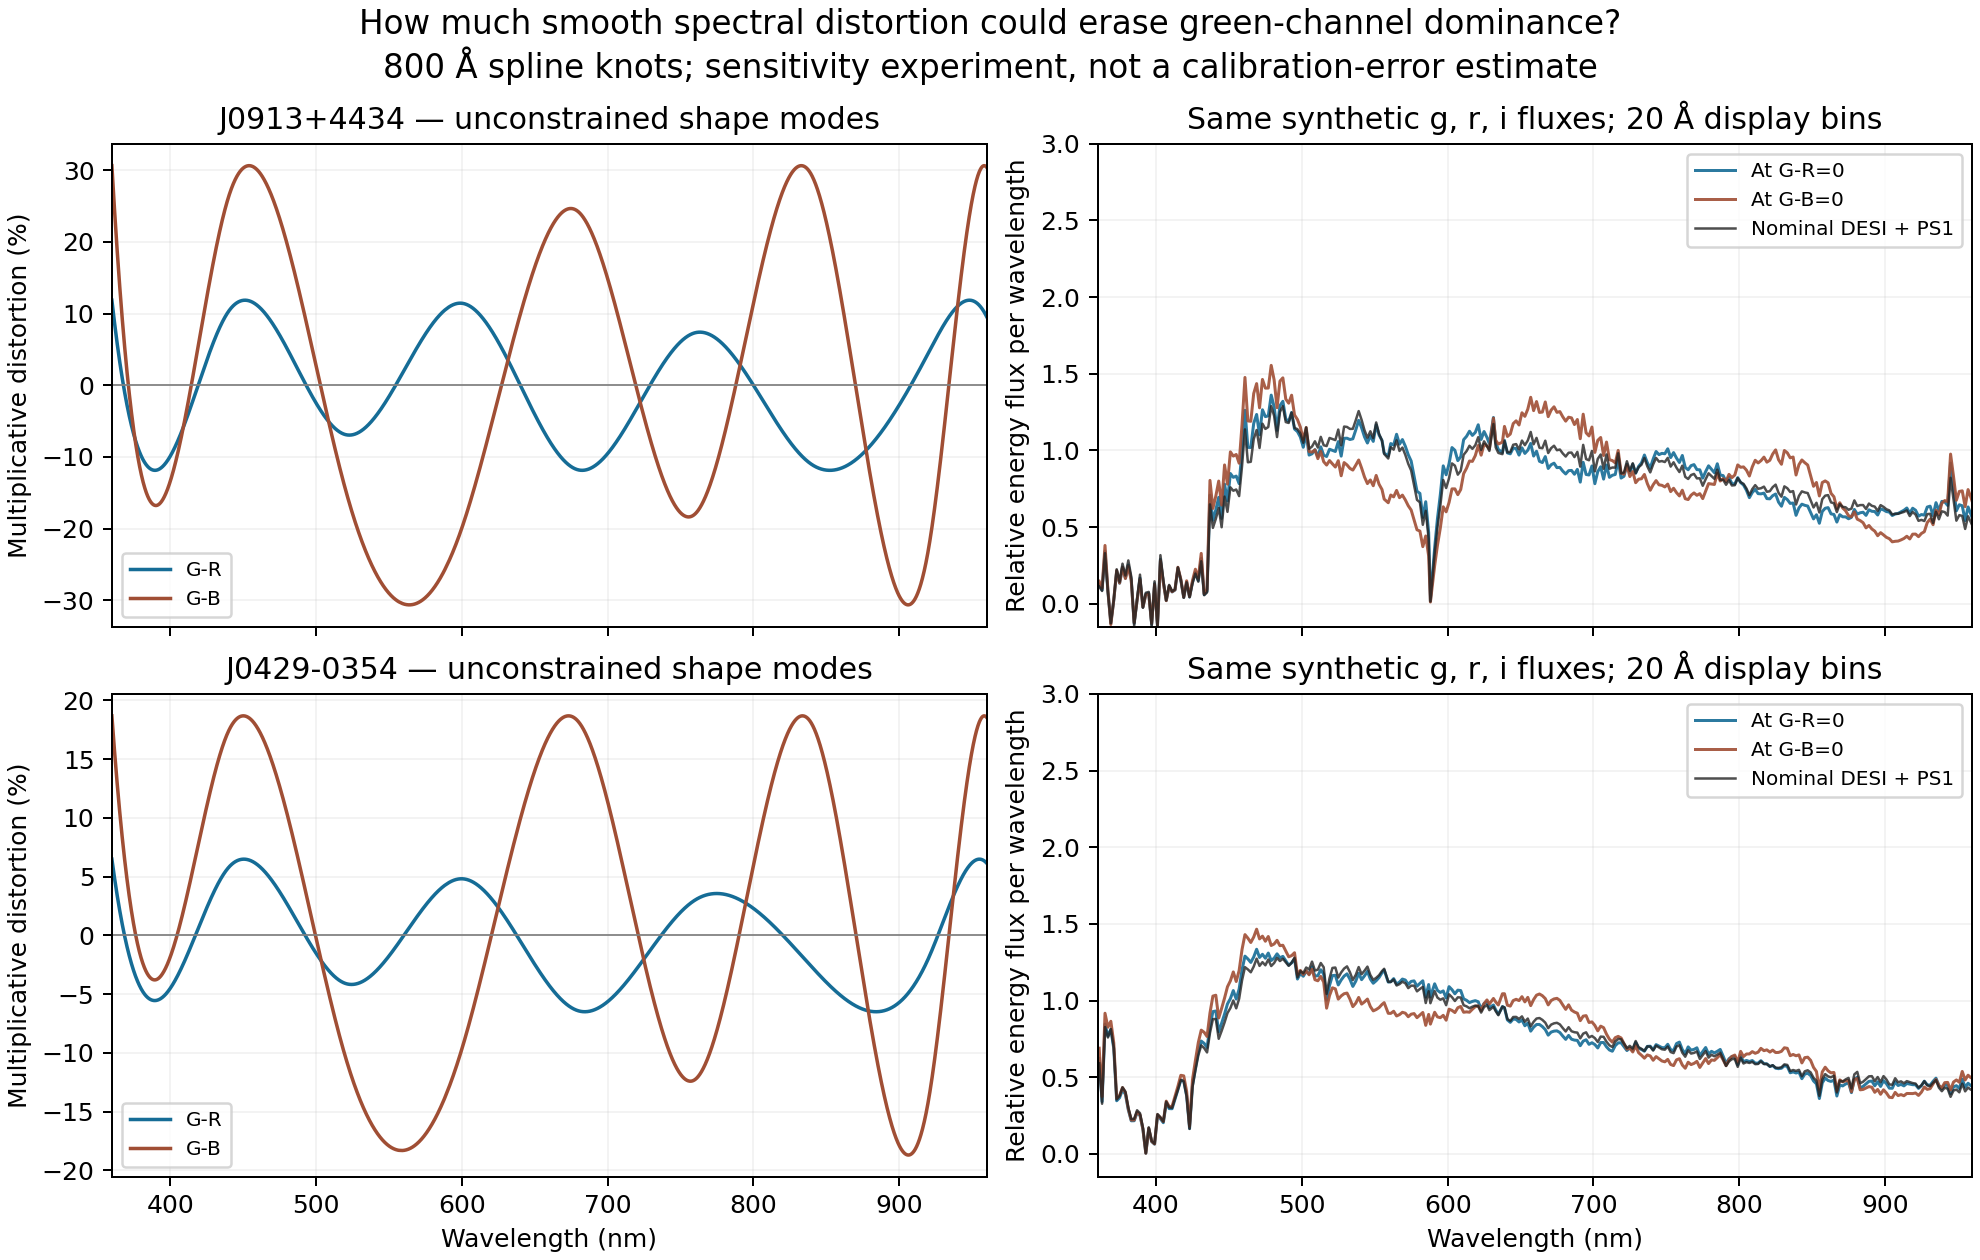

In [13]:
show_figure('research/precision/photometric_nullspace.png')

図は表の800 Åシナリオです。右の曲線は同じ合成griを持ち、表示のためだけに20 Åでまとめています。griとの一致だけでは制約できない形状の自由度があるため、相対分光較正や追加の未使用バンドの制約が必要です。

生成元：`precision/photometric_nullspace.py`。新しい校正誤差が見つかったと解釈せず、必要な校正精度や追加観測を設計するための感度実験として使います。

### 6. 一件ずつの監査と、残っている範囲

「全入力にプログラムを適用した」「要点検entityを抽出した」「図の全panelを見た」は、異なる単位の作業です。次の表はその違いを保って集計します。

In [14]:
coverage = pd.DataFrame([
    {'作業': '全入力へのプログラム監査', '件数': census['records'], '単位': 'スペクトル記録'},
    {'作業': '追加点検フラグのある集合', '件数': census['review_entities'], '単位': 'entity key'},
    {'作業': '個別コメントを持つ目視済み集合', '件数': len(visual_index), '単位': 'entity key'},
    {'作業': '目視済み画像snapshot', '件数': visual_index.contact_sheet.nunique(), '単位': '画像ページ'},
])
show_table(coverage, {'件数': '{:,}'})
display(Markdown(f"個別の目視記録は **{len(visual_index)}/{census['review_entities']:,}要点検entity**です。元の強い外れ値の全panelをカバーしますが、全要点検対象の目視を完了したという主張ではありません。"))

作業,件数,単位
全入力へのプログラム監査,"9,902",スペクトル記録
追加点検フラグのある集合,"2,344",entity key
個別コメントを持つ目視済み集合,337,entity key
目視済み画像snapshot,22,画像ページ


個別の目視記録は **337/2,344要点検entity**です。元の強い外れ値の全panelをカバーしますが、全要点検対象の目視を完了したという主張ではありません。

[前半の個別目視記録](outlier_audit/visual_review_01_11.md) と [後半の個別目視記録](outlier_audit/visual_review_12_22.md) には、各panelの観察、ID、注意点、見た画像のSHAを残しました。[全候補の既存研究・露出台帳](literature/outputs/candidate27_prior_inventory.csv) と、[全entityの監査表](outlier_audit/object_audit.csv) も参照できます。

深い吸収の付近での正規化、表示範囲の切れ、負画素、XPの振動だけで、変光・元素・検出器故障を断定しません。個別図の確認は、全元画素・全原FITS・全近傍像を調べたこととも区別します。

### 証拠の独立性

| 比較 | 得られる点検 | 残る共有情報・限界 |
|---|---|---|
| MWDD SDSSとSDSS直接配布 | 同一元観測なら単位・標本の検算 | 同じ画素由来のコピーを独立観測として増やさない。 |
| DESIの別夜 | 形状の再現、カメラ欠損、時間差 | 装置・処理系を共有。同じPS1アンカーなら較正も共通。 |
| Gaia fullとtruncated | 基底打切りに対する感度 | 同じXP係数からの再構成。 |
| PS1 griと未使用z | 較正外バンドへの予測残差 | 同じ測光サーベイ。iの赤端との波長重複と非同時性。 |
| ZTFとDESI | 別装置・別epochでの光度や位置の点検 | ZTFの絶対較正にPS1が関係する。検出のみの光度曲線はforced photometryではない。 |

ZTFの位置不一致イベントも削除せず、元の検出と画像切り抜きを残しています。[外部観測の結果](external_validation/README.md) で確認できます。

## 学術的価値に向けた、反証可能な次の仮説

| 仮説 | 今回の根拠 | 次に比較するもの | 仮説を弱める結果 |
|---|---|---|---|
| 固定CI金属比ではDZの形状を説明しきれない | Kilic2026の既存fitはCaを調整し他の金属を固定。今回の色と未使用帯域が追加診断になる。 | Na/Ca・Mg/Caを自由にしたモデルと、滑らかな較正傾斜だけを許すモデル。探索外の波長・別装置で予測を評価する。 | 自由元素比で未使用データの予測が改善しない、または較正誤差だけで同じ改善を説明できる。 |
| J1323−0129や低質量DQの解は大気仮定／未分離伴星に敏感 | 公刊モデル間の温度・質量・元素量の変化、今回のz残差、低質量DQに対する既存の警告。 | Gaia距離を使う絶対SED、H/He・CIA・金属線翼、単星／二成分SEDを同じ誤差モデルで比較する。 | 一貫した単星モデルで予測できる、または追加自由度が予測を改善しない。 |
| C$_2$帯の位置と深さは圧力・炭素量・磁場を区別する診断になる | DQ/DQpec分類差と、別夜でも残る分子帯。圧力シフト自体は既知。 | 帯位置と深さを連続光傾斜から分離し、既知DQpec・磁気DQを対照にする。 | 装置の波長・形状誤差や磁気歪みと識別できない。 |
| 色外れ値と分類不一致の組合せが、専門モデルの失敗例を選べる | 単位・欠損・ID監査で候補の意味が変化した。 | 相関較正誤差を含む擬似観測で回収率と偽陽性を測り、探索に使わないサーベイ部分で性能を検証する。 | 外部データでの性能が改善しない、または選択・混入で説明される。 |

先行研究：[Kilic2025](https://arxiv.org/abs/2412.04611)、[Kilic2026](https://arxiv.org/html/2606.25377v2)、[Blouin & Dufour2019](https://arxiv.org/html/1910.06168v1)。候補ごとの値と、既知研究との重複は [literature/README.md](literature/README.md) にまとめています。

PEWDDの照合も研究の前提です。名前・座標・Gaiaの不整合には「Gaia IDの誤対応」と「IDは正しく座標だけが誤対応」の両方があり、flag集合を一律に誤IDと扱いません。[一次データによる独立確認](literature/independent_key_audit.md) を参照してください。

物理的な新発見にするには、既知の色機構の再現から進み、**どのモデル仮定が未使用データで破れるか、代替説明をどこまで棄却できるか**を示す必要があります。

## 再現と検証

このノートブックは保存済み表を読む軽量な伴走資料です。原観測から結果までの数値的な不変条件は、次の別スクリプトで検証できます。全サーベイの再取得は必要ありません。

```bash
python scripts/verify_reproduction.py
python scripts/verify_research_extension.py
python -m jupyter nbconvert --execute --to notebook --inplace research/research_extension.ipynb
```

`verify_research_extension.py` は任意の作業ディレクトリから `--root /path/to/repo` でも実行できます。元係数からのGaia再構築、PS1の実際の再積分、splineの連続極値、目視記録と画像ハッシュ、元ZTF検出の保持を点検します。Monte Carlo、GaiaXPy、LPそのものをすべて再実行する検証ではありません。

In [15]:
assert verification['status'] == 'PASS', '保存済み研究検証が未通過です'
groups = pd.DataFrame(verification['groups'])[['name', 'status']].rename(columns={'name': '保存済み検証群', 'status': '結果'})
show_table(groups)
display(Markdown(f"検証レポート日時：`{verification['created_utc']}`。保存済みレポートは **{len(verification['verified_file_sha256'])}ファイル**のハッシュを記録しています。上のコマンドで現時点の入力に対して再実行できます。"))

# 本ノートブックが読んだ入力のうち、検証レポートにも載るものは実際に再照合する。
shared_inputs = set(input_hashes) & set(verification['verified_file_sha256'])
for relative in shared_inputs:
    assert input_hashes[relative] == verification['verified_file_sha256'][relative], relative
display(Markdown(f"この実行でも、ノートブック入力と検証レポートの共通 **{len(shared_inputs)}ファイル**のSHA256が一致しました。"))

保存済み検証群,結果
corrected screen and unit registry,PASS
Gaia coefficient/covariance reconstruction,PASS
PS1 calibration and held-out z,PASS
photometric nullspace witnesses,PASS
visual review provenance,PASS
DESI individual exposures,PASS
ZTF native epochs and offset event,PASS


検証レポート日時：`2026-10-18T16:53:00.796513+00:00`。保存済みレポートは **249ファイル**のハッシュを記録しています。上のコマンドで現時点の入力に対して再実行できます。

この実行でも、ノートブック入力と検証レポートの共通 **3ファイル**のSHA256が一致しました。